![Banner](Banner.jpg)

# Definición de un MDP para Gridworld

En este tutorial vamos a definir un ambiente de prueba comúnmente utilizado en el aprendizaje por refuerzo; el ambiente de Gridworld. Vamos a definir el ambiente de Gridworld como un Markov Decision Process (MDP) para luego establecer solución con los diferentes métodos basados en modelos y libres de modelos.
Gridworld es un ambiente clásico de prueba dentro del aprendizaje por refuerzo. Durante este tutorial definiremos el modelo básico del ambiente, que extenderemos incrementalmente de acuerdo con las necesidades de los algoritmos específicos de solución que desarrollaremos a lo largo del curso.

Los ambientes de aprendizaje por refuerzo se pueden definir en dos (ambiente, agente) o tres (ambiente, agente, aprendizaje) módulos. Por simplicidad, dentro de nuestra implementación de Gridworld (e implementaciones posteriores) utilizaremos dos módulos. Sin embargo, cabe notar que una implementación utilizando tres módulos ofrece una mejor división de las características y por lo tanto una implementación más fácil de mantener y modificar.

Para cada uno de los módulos a continuación daremos una clase principal de código sobre la cual se deben hacer todas las modificaciones. Cada una de las funciones a implementar se presentarán progresivamente. Para cada una de las funciones a implementar se dará un conjunto (mínimo) de prueba.


## Ambiente 🌎

El ambiente de Gridworld se define como una cuadricula de `nxm`. El ambiente tiene obstáculos, es decir casillas por las cuales no puede pasar el agente. Al chocar con un obstáculo, el agente termina en la misma casilla en la que estaba. Un comportamiento similar se observa cuando el agente trata de salir de los bordes del ambiente. Además, el ambiente tiene una casilla de inicio definida, y algunas casillas de salida (determinadas por la recompensa asociada a ellas). Un ejemplo del ambiente para el caso `3x4` se muestra a continuación.

![gridworld.png](gridworld.png)

En este ejemplo del ambiente la casilla de inicio es la casilla inferior izquierda y tiene como objetivo llegar a la casilla de salida con recompensa 1. La otra casilla de salida tiene recompensa -1.


#### ¿Cómo podemos codificar el ambiente?

La definición del ambiente de Gridworld esta definida por:
1. Una cuadrícula rectangular (`grid`), con dimensiones `(n,m)` dadas por parámetro, donde la casilla superior izquierda esta en la posición (0,0). Definiremos las casillas por las que puede pasar el agente como espacios en blanco y las casillas por las que no puede pasar el agente con un `'#'`.
2. Las recompensas de cada casilla de la cuadrícula estan definidas dentro de la definición de `grid`.
    - +1 para la casilla objetivo 
    - -1 para las casillas de trampa
3. Un atributo con el estado actual (`state`) en el que se encuentra el agente. Por defecto este estado será la posición marcada como `S`.

Un ejemplo de una cuadrícula de 3x4, como se mostró anteriormente, sería así:

 ```python  
    board = [[' ', ' ', ' ',  +1],
            [' ', '#', ' ',  -1],
             ['S', ' ', ' ', ' ']] 
```

La definición del ambiente un ejemplo de recompensas se vería así: 

```python
    def __init__(self, board):
        # layout
        self.grid = copy_elements_from_the_board
```


#### 1. Estructura del ambiente

Defina la clase `Gridworld`, que recibe una cuadrícula con la descripción del tablero `board`, definidos como en el ejemplo. La información codificada en la cuadrícula será almacenada en el atributo `grid` del ambiente (este atributo corresponde al mdp donde se almacena la información del ambiente, la función de transición y las recompensas). Adicionalmente, para facilitar el uso del mdp, definimos los atributos para guardar la información de la cuadrícula; las filas (`nrows`) y columnas (`ncols`). esta información se da por parámetro (`dimensions`), al instanciar la clase, como una tupla con los valores respectivos. Adicionalmente la clase debe tener los atributos `initial_state` y `state` que corresponden al estado inicial y el estado actual del agente en el ambiente, respectivamente. Estos atributos se guardan como tuplas.

Finalmente, el atributo `grid` se debe codificar de tal forma que las casillas prohibidas (marcadas como `'#'`) no deben tener ningún valor asignado (su valor debe ser `None`), las casillas en blanco deben tener valor `0`, y las casillas con recompensas asociadas deben tener el valor de la recompensa como su valor. Note que con esta codificación de `grid`, y teniendo en cuenta que las acciones son determinísticas, estamos codificando directamente las recompensas del ambiente. Si este no fuera el caso, sería necesario definir un nuevo atributo `rewards`.

In [16]:
#Definición del ambiente de gridworld

#Librerias de gráficas
import matplotlib.pyplot as plt
import matplotlib.patches as patches

#Definición de la clase principal
class Gridworld:
    def __init__(self, board : list[list[str]], dimensions: tuple[int,int]):
        # your code here
        self.nrows, self.ncols = dimensions
        if len(board) != self.nrows or any(len(row) != self.ncols for row in board):
            raise ValueError("Las dimensiones no coinciden con el tablero")

        self.grid = []
        starts = []
        for i, row in enumerate(board):
            values = []
            for j, cell in enumerate(row):
                if cell == 'S':
                    starts.append((i, j))
                if cell == '#':
                    value = None
                elif cell in (' ', 'S'):
                    value = 0
                else:
                    value = int(cell)
                values.append(value)
            self.grid.append(values)

        if len(starts) != 1:
            raise ValueError("El tablero debe contener exactamente una S")
        self.initial_state = starts[0]
        self.state = self.initial_state
        self.moves = {
            'up': (-1, 0),
            'down': (1, 0),
            'left': (0, -1),
            'right': (0, 1),
        }
    
    def get_current_state(self) -> tuple[int,int]:
        # your code here
        return self.state
    
    def get_possible_actions(self, state: tuple[int, int]) -> list[str]:
        # INICIO CAMBIO: acciones según el enunciado, incluidos los choques.
        i, j = state
        if not (0 <= i < self.nrows and 0 <= j < self.ncols):
            raise ValueError("Estado fuera del tablero")
        if self.grid[i][j] is None:
            return []
        if self.grid[i][j] in (1, -1):
            return ['exit']
        return ['up', 'right', 'down', 'left']
        # FIN CAMBIO
    
    def do_action(self, action: str, model='deterministic', rng=None):
        # INICIO CAMBIO: misma API básica, con modelos probabilísticos opcionales.
        import random
        distribution = self.get_transition_distribution(self.state, action, model)
        generator = rng if rng is not None else random
        destinations = list(distribution)
        self.state = generator.choices(
            destinations, weights=list(distribution.values()), k=1
        )[0]
        # La recompensa se entrega al llegar; exit no la vuelve a entregar.
        reward = 0 if action == 'exit' else self.grid[self.state[0]][self.state[1]]
        return reward, self.state
        # FIN CAMBIO

    def reset(self):
        # INICIO CAMBIO: el enunciado especifica que reset no retorna un valor.
        self.state = self.initial_state
        # FIN CAMBIO
    
    def is_terminal(self) -> bool:
        # your code here
        i, j = self.state
        return self.grid[i][j] in (1, -1)
    
    #Funciones auxiliares
    def get_action_index(self, action:str) -> int:
        actions = ['up', 'right', 'down', 'left']
        index = 0
        for a in actions:
            if action == a:
                return index
            index += 1
            
    def plot(self):
        fig1 = plt.figure(figsize=(10, 10))
        ax1 = fig1.add_subplot(111, aspect='equal')
        
        # Lineas
        # INICIO CAMBIO: dibujar correctamente tableros rectangulares.
        for i in range(self.nrows + 1):
            ax1.axhline(i, linewidth=2, color="#2D2D33")
        for j in range(self.ncols + 1):
            ax1.axvline(j, linewidth=2, color="#2D2D33")
        # FIN CAMBIO
        
        # Amarillo - estado inicial
        (i,j)  = self.initial_state
        ax1.add_patch(patches.Rectangle((j, self.nrows - i -1), 1, 1, facecolor = "#F6D924"))
        for j in range(len(self.grid[0])):
            for i in range(len(self.grid)):
                if self.grid[i][j] == 1: # verde
                    ax1.add_patch(patches.Rectangle((j,self.nrows - i -1), 1, 1, facecolor = "#68FF33"))
                if self.grid[i][j] == None: # gris
                    ax1.add_patch(patches.Rectangle((j,self.nrows - i -1), 1, 1, facecolor = "#6c7780"))
                if self.grid[i][j] == -1: # rojo
                    ax1.add_patch(patches.Rectangle((j,self.nrows - i -1), 1, 1, facecolor = "#cc0000"))
        plt.scatter(self.state[1] + 0.5, self.nrows - self.state[0] - 1 +0.5, s = 100, color = "black", marker = "o", facecolor = "blue", edgecolors = "blue", zorder = 10)
        for i in range(len(self.grid)):
            for j in range(len(self.grid[0])):
                if self.grid[i][j] == None:
                    ax1.text(self.ncols-j-1, self.nrows-i-1, "", ha='center', va='center')
                else:
                    ax1.text(j+0.5, self.nrows-i-1+0.5, self.grid[i][j], ha='center', va='center')
        plt.axis("off")
        plt.show()
    
    # INICIO CÓDIGO NUEVO: modelo explícito del MDP para las reflexiones.
    def get_transition_distribution(self, state, action, model='deterministic'):
        """Devuelve {estado_siguiente: probabilidad}, sin modificar el ambiente."""
        models = ('deterministic', 'uniform', 'clockwise')
        if model not in models:
            raise ValueError(f"Modelo desconocido: {model}")
        if action not in self.get_possible_actions(state):
            raise ValueError(f"Acción {action!r} no permitida en {state}")
        if action == 'exit':
            return {state: 1.0}

        actions = ['up', 'right', 'down', 'left']
        if model == 'deterministic':
            outcomes = [(action, 1.0)]
        elif model == 'uniform':
            outcomes = [(direction, 0.25) for direction in actions]
        else:
            clockwise = actions[(self.get_action_index(action) + 1) % 4]
            outcomes = [(action, 0.60), (clockwise, 0.30), (None, 0.10)]

        distribution = {}
        i, j = state
        for direction, probability in outcomes:
            di, dj = self.moves[direction] if direction is not None else (0, 0)
            ni, nj = i + di, j + dj
            if not (0 <= ni < self.nrows and 0 <= nj < self.ncols) or self.grid[ni][nj] is None:
                destination = state
            else:
                destination = (ni, nj)
            distribution[destination] = distribution.get(destination, 0.0) + probability
        return distribution

    def expected_reward(self, state, action, model='deterministic'):
        """Recompensa inmediata esperada R(s,a); no es el valor acumulado V(s)."""
        distribution = self.get_transition_distribution(state, action, model)
        if action == 'exit':
            return 0.0
        return sum(probability * self.grid[i][j]
                   for (i, j), probability in distribution.items())
    # FIN CÓDIGO NUEVO


In [17]:
#Pruebas estructura del ambiente
### BEGIN TESTS
board = [[' ', ' ', '-1'],
      ['S', '#', ' '],
      [' ', ' ', '+1']]

grid = Gridworld(board, (3,3))

try:
    grid.nrows
except:
    print("El atributo nrows no está definido")
try:
    grid.ncols
except:
    print("El atributo ncols no está definido")
try:
    grid.initial_state
except:
    print("El atributo initial_state no está definido")

try:
    grid.state
except:
    print("El atributo state no está definido")

try:
    grid.grid
except:
    print("El atributo grid no está definido")

assert grid.ncols == 3, "El valor de las columnas debe ser el dado por parámetro en el atributo dimensions"
assert grid.nrows == 3, "El valor de las columnas debe ser el dado por parámetro en el atributo dimensions"
assert grid.grid[1][1] == None, "El valor de las casillas sobre las que no puede pasar el agente debe ser None"
assert grid.grid[0][2] == -1, "El valor de las casillas con recompensa debe ser el valor numérico (tipo int)"
assert grid.initial_state == (1,0), "La posición inicial del agente debe ser la definida en el estado S de la cuadrícula dada"
assert grid.initial_state == grid.state, "La posición del agente debe ser igual a su posición inicial si ningún paso se ha dado"
### END TESTS

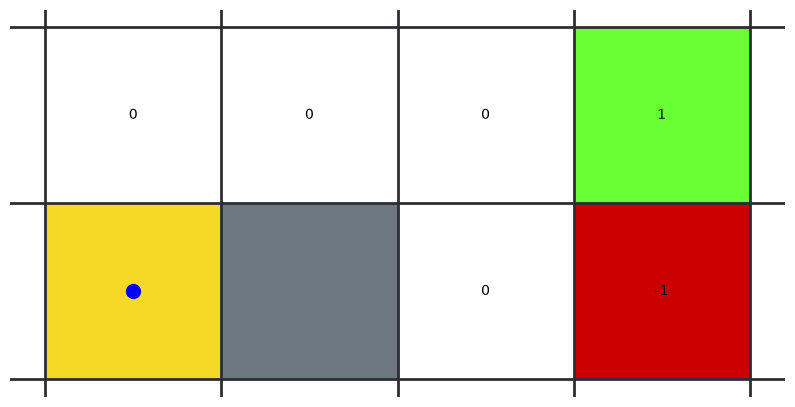

In [18]:
# Pruebas adicionales
# INICIO CÓDIGO NUEVO: tablero rectangular y copia independiente.
rectangular_board = [[' ', ' ', ' ', '+1'], ['S', '#', ' ', '-1']]
rectangular = Gridworld(rectangular_board, (2, 4))
assert rectangular.initial_state == (1, 0)
assert rectangular.nrows == 2 and rectangular.ncols == 4
assert rectangular.grid[1][1] is None
assert rectangular_board[1][0] == 'S'
rectangular.plot()
# FIN CÓDIGO NUEVO

#### 2. Movimientos del agente

Defina la función `do_action` que ejecuta la acción tomada por el agente dentro de la cuadrícula. Esta función recibe como parámetro la acción a ejecutar y retorna el valor de la casilla de llegada de la acción y el estado de llegada de la acción (como una tupla). Note que los movimientos fuera del tablero o las casillas prohibidas no deberían tener ningún efecto en la posición del agente (el agente se debe mantener en la misma posición de partida).

En esta versión de gridworld vamos a trabajar con acciones determinísticas, es decir el movimiento deseado del agente (`up`,`right`,`down`,`left`) siempre resultara en el estado esperado. 


In [19]:
#Pruebas de movimiento
### BEGIN TESTS
board = [[' ', ' ', '-1'],
      ['S', '#', ' '],
      [' ', ' ', '+1']]

grid = Gridworld(board, (3,3))

try:
    grid.do_action
except:
    print("La función do_action no está definida")

val, state = grid.do_action('up')
assert state == (0,0), f"El movimiento hacia arriba no esta modificando correctamente al agente, se movió a {state} y debería ser (0,0)"
val, state = grid.do_action('right')
assert state == (0,1), f"El movimiento hacia la derecha no esta modificando correctamente al agente, se movió a {state} y debería ser (0,1)"
val, state = grid.do_action('right')
assert val == -1, f"El valor de las casillas no se esta retornando correctamente"
# INICIO CAMBIO: en una salida solo se permite exit, según la sección 4.
assert grid.is_terminal()
assert grid.get_possible_actions(grid.state) == ['exit']
assert grid.do_action('exit') == (0, (0, 2))
# Preparar un estado regular para probar el choque con el obstáculo.
grid.state = (1, 2)
# FIN CAMBIO
val, state = grid.do_action('left')
assert state == (1,2), f"El movimiento hacia la derecha no esta modificando correctamente al agente, se movió a {state} y debería ser (1,2) porque hay un obstáculo en (1,1)"

### END TESTS

In [20]:
# Pruebas adicionales
# INICIO CÓDIGO NUEVO: límites, obstáculos y entrada a una salida.
grid.reset()
assert grid.do_action('left') == (0, (1, 0))
assert grid.do_action('right') == (0, (1, 0))
assert grid.do_action('down') == (0, (2, 0))
assert grid.do_action('right') == (0, (2, 1))
assert grid.do_action('right') == (1, (2, 2))
assert grid.is_terminal()
assert grid.do_action('exit') == (0, (2, 2))
grid.reset()
# FIN CÓDIGO NUEVO

#### 3. Estado actual

Defina la función `get_current_state` que retorna el estado actual del agente (la casilla donde se encuentra el agente). Esta función no recibe ningún parámetro y retorna el estado actual como una tupla.

In [21]:
#Pruebas estado actual
### BEGIN TESTS
board = [[' ', ' ', '-1'],
      ['S', '#', ' '],
      [' ', ' ', '+1']]

grid = Gridworld(board, (3,3))

try:
    grid.get_current_state
except:
    print("La función get_current_state no está definida")

assert grid.get_current_state() == (1,0), "La posición del agente debe ser la posición inicial si no se realiza ningún movimeinto"
grid.do_action('up')
assert grid.get_current_state() == (0,0), f"La posición del agente no se esta modificando correctamente, recibió {grid.get_current_state()} cuando debería ser (0,0), revise los movimientos"
grid.state = (1,0)
grid.do_action('right')
assert grid.get_current_state() == (1,0), "El agente no se mantiene en la misma posición cuando trata de moverse a la casilla prohibida"
### END TESTS

In [22]:
#Pruebas adicionales



#### 4. Obtener las acciones

Defina la función `get_possible_actions` que recibe el estado actual del agente por parámetro y retorna una lista de las acciones válidas para el estado dado.

Tenga en cuenta que en esta versión de Gridworld, todas las acciones (i.e., los movimientos en las cuatro direcciones) son posibles para el agente en cada una de las casillas regulares de la cuadrícula. Las casillas de salida tienen única acción posible `'exit'` y las casillas prohibidas no tienen ningúna acción asociada (una lista vacía de acciones).

In [23]:
#Pruebas de acciones posibles
### BEGIN TESTS
board = [[' ', ' ', '-1'],
      ['S', '#', ' '],
      [' ', ' ', '+1']]

grid = Gridworld(board, (3,3))

try:
    grid.get_possible_actions
except:
    print("La función get_possible_actions no está definida")

a1 = grid.get_possible_actions(grid.state)
a2 = grid.get_possible_actions((1,0))
a3 = grid.get_possible_actions((1,2))
a4 = grid.get_possible_actions((0,1))
a5 = grid.get_possible_actions((2,1))
ap = grid.get_possible_actions((1,1))
ar1 = grid.get_possible_actions((0,2))
ar2 = grid.get_possible_actions((2,2))
assert ap == [], "Las acciones para las casillas prohibidas deben estar vacias"
assert a1 == a2 == a4 == a5, f"Todas las casillas regulares deben tener el mismo conjunto de acciones {['up', 'right', 'down', 'left']}"
assert ar1 == ar2, f"Todas las casillas de salida deben tener el mismo conjunto de acciones {['exit']}"
### END TESTS

In [24]:
# Pruebas adicionales
# INICIO CÓDIGO NUEVO: conjuntos exactos de acciones del tutorial.
assert grid.get_possible_actions((1, 0)) == ['up', 'right', 'down', 'left']
assert grid.get_possible_actions((1, 1)) == []
assert grid.get_possible_actions((0, 2)) == ['exit']
assert grid.get_possible_actions((2, 2)) == ['exit']
# FIN CÓDIGO NUEVO


#### 5. Reinicializar el ambiente

Defina la función `reset` que no recibe parámetros ni retorna ningún valor. El efecto de esta función es restablecer el ambiente a su estado inicial.



In [25]:
#Pruebas de reset
### BEGIN TESTS
board = [[' ', ' ', '-1'],
      ['S', '#', ' '],
      [' ', ' ', '+1']]

grid = Gridworld(board, (3,3))

try:
    grid.reset
except:
    print("La función reset no está definida")

grid.state = (2,2)
grid.reset()
assert grid.get_current_state() == grid.initial_state, f"No se esta retornando al estado inicial. {grid.get_current_state()} y no {grid.initial_state}"
grid.state = (1,1)
grid.reset()
assert grid.get_current_state() == grid.initial_state, f"No se esta retornando al estado inicial. {grid.get_current_state()} y no {grid.initial_state}"
### END TESTS

In [26]:
# Pruebas adicionales
# INICIO CÓDIGO NUEVO: reset restaura el inicio y devuelve None.
assert grid.reset() is None
assert grid.state == grid.initial_state
# FIN CÓDIGO NUEVO


#### 6. Estados terminales

Defina la función `is_terminal` que determina si el agente está en un estado final o no. En nuestro caso los estados finales o los estados de salida estarán determinados por las casillas con recompensa 1 o -1.
Esta función no recibe parámetros y retorna un booleano determinando si el agente está en un estado final o no.

In [27]:
#Pruebas terminación
### BEGIN TESTS
board = [[' ', ' ', '-1'],
      ['S', '#', ' '],
      [' ', ' ', '+1']]

grid = Gridworld(board, (3,3))

try:
    grid.is_terminal
except:
    print("La función is_terminal no está definida")

grid.state = (2,2)
assert grid.is_terminal() == True, f"No se identifican correctamente los estados de salida como finales"
grid.state = (0,2)
assert grid.is_terminal() == True, f"No se identifican correctamente los estados de salida como finales"

for i in range(grid.nrows):
    for j in range(grid.ncols):
        grid.state = (i,j)
        if (i,j) == (0,2) or (i,j) == (2,2):
            assert grid.is_terminal() == True, f"No se identifican correctamente los estados de salida como finales"
        else:
            assert grid.is_terminal() == False, f"La casilla {(i,j)} se estan identificando como estado final"

### END TESTS

In [28]:
#Pruebas adicionales



## Preguntas de reflexión

Considere las siguientes situaciones y piense cual debería ser el resultado del MDP.

1. Plantee el problema de MDP para cada una de las casillas. Especifique el estado de inicio, las transiciones y su probabilidad. Para cada acción suponga una probabilidad de éxito de 0.25 (el 0.75 restante se resuelve uniformemente entre las acciones restantes).
¿Cómo serían las recompensas esperadas para cada estado?

2. Bajo la definción del problema anterior, suponga que ahora cada acción tiene una probabilidad de éxito de 60%, con probabilidad de 30% que se ejecutará la sigiente acción (en dirección de las manesillas del reloj) y con probabilidad de 10% que no se ejecute ninguna acción (el agente se queda quieto). Bajo estas condiciones, ¿Cómo serían las recompensas esperadas para cada estado? 


## Cambios y convenciones para revisar

**CÓDIGO NUEVO / CAMBIO:** los comentarios con estas etiquetas delimitan las modificaciones.

- `get_possible_actions` devuelve las cuatro direcciones en cada estado regular, `['exit']` en las salidas y `[]` en obstáculos. Chocar con un borde u obstáculo conserva la posición.
- `do_action` admite los modelos `deterministic` (por defecto), `uniform` y `clockwise`, y un generador `rng` para reproducir simulaciones. La prueba original que intentaba ejecutar `down` desde una salida se corrigió para usar `exit`, conforme al enunciado. Una acción no permitida genera `ValueError`.
- La recompensa se recibe **al entrar** a la casilla. `is_terminal()` identifica las salidas ±1; `exit` conserva esa posición con recompensa 0 y representa el fin del episodio. No se vuelve a cobrar la recompensa terminal. El bucle de simulación se detiene al llegar a una salida.
- `reset` no retorna un valor. `plot` dibuja filas y columnas por separado para admitir tableros rectangulares.
- Se añadieron transiciones explícitas, recompensas esperadas y pruebas en las celdas reservadas para pruebas adicionales. Se preservan las otras pruebas originales.

### Respuesta a las situaciones finales

Se usa el tablero 3×3 de las pruebas: inicio **(1, 0)**, obstáculo **(1, 1)** y salidas **(0, 2)** con −1 y **(2, 2)** con +1. Los estados son todas las casillas transitables. La celda siguiente enumera las transiciones de **cada par estado–acción** y sus probabilidades.

1. **Éxito 0.25:** cada una de las otras tres direcciones tiene probabilidad 0.75/3 = 0.25. La acción elegida no altera la distribución. Si `T(s,d)` aplica una dirección respetando choques, entonces `P(s'|s,a) = Σ_d 0.25 · 1[T(s,d)=s']`. Las probabilidades que llegan al mismo destino se suman. Las recompensas inmediatas esperadas son −0.25 en (0,1), +0.25 en (2,1), y 0 en los demás estados regulares; en (1,2) las contribuciones +1 y −1 se cancelan.
2. **Éxito 0.60:** `P(s'|s,a) = 0.60 · 1[T(s,a)=s'] + 0.30 · 1[T(s,siguiente_horaria(a))=s'] + 0.10 · 1[s=s']`. El orden horario es `up → right → down → left → up`. Ahora la recompensa depende de la acción: en (0,1), elegir `up` da −0.30 y `right` da −0.60; en (2,1), `up` da +0.30 y `right` da +0.60. En (1,2), `up`, `right`, `down`, `left` dan, respectivamente, −0.60, +0.30, +0.60, −0.30. Las demás casillas regulares dan 0 para todas las acciones.

En ambos casos `R(s,a) = Σ_s' P(s'|s,a) · r(s')` para estados regulares; en las salidas, `exit` tiene recompensa adicional 0. Las tablas muestran `R(s,a)` para todas las acciones: no hay una única recompensa esperada por estado sin fijar una política. Para una política π, `Rπ(s) = Σ_a π(a|s) R(s,a)`. También se muestra la política uniforme (cada acción regular con probabilidad 1/4): sus promedios son iguales en las dos situaciones. Esto es recompensa **inmediata**, no retorno acumulado ni valor óptimo; esos últimos requieren definir descuento y política o un algoritmo de solución.


In [29]:
# INICIO CÓDIGO NUEVO: MDP completo de las dos situaciones y sus recompensas.
from IPython.display import Markdown, display
import random

reflection_board = [[' ', ' ', '-1'], ['S', '#', ' '], [' ', ' ', '+1']]
reflection = Gridworld(reflection_board, (3, 3))
reflection_states = [(i, j) for i in range(reflection.nrows)
                     for j in range(reflection.ncols) if reflection.grid[i][j] is not None]

for model, title in [('uniform', 'Situación 1: 25% por dirección'),
                     ('clockwise', 'Situación 2: 60% / 30% horario / 10% quieto')]:
    rows = ['| Estado | Acción | Destinos y probabilidades | R(s,a) |',
            '|---|---|---|---:|']
    averages = []
    for state in reflection_states:
        actions = reflection.get_possible_actions(state)
        rewards = []
        for action in actions:
            distribution = reflection.get_transition_distribution(state, action, model)
            assert abs(sum(distribution.values()) - 1) < 1e-12
            assert all(p > 0 and reflection.grid[s[0]][s[1]] is not None
                       for s, p in distribution.items())
            reward = reflection.expected_reward(state, action, model)
            rewards.append(reward)
            destinations = '; '.join(f'{s}: {p:.2f}' for s, p in sorted(distribution.items()))
            rows.append(f'| {state} | {action} | {destinations} | {reward:+.2f} |')
        averages.append(f'| {state} | {sum(rewards) / len(rewards):+.2f} |')
    display(Markdown('### ' + title + '\n\n' + '\n'.join(rows)))
    display(Markdown('**Recompensa esperada por estado con política uniforme**\n\n'
                     '| Estado | Rπ(s) |\n|---|---:|\n' + '\n'.join(averages)))
# FIN CÓDIGO NUEVO

### Situación 1: 25% por dirección

| Estado | Acción | Destinos y probabilidades | R(s,a) |
|---|---|---|---:|
| (0, 0) | up | (0, 0): 0.50; (0, 1): 0.25; (1, 0): 0.25 | +0.00 |
| (0, 0) | right | (0, 0): 0.50; (0, 1): 0.25; (1, 0): 0.25 | +0.00 |
| (0, 0) | down | (0, 0): 0.50; (0, 1): 0.25; (1, 0): 0.25 | +0.00 |
| (0, 0) | left | (0, 0): 0.50; (0, 1): 0.25; (1, 0): 0.25 | +0.00 |
| (0, 1) | up | (0, 0): 0.25; (0, 1): 0.50; (0, 2): 0.25 | -0.25 |
| (0, 1) | right | (0, 0): 0.25; (0, 1): 0.50; (0, 2): 0.25 | -0.25 |
| (0, 1) | down | (0, 0): 0.25; (0, 1): 0.50; (0, 2): 0.25 | -0.25 |
| (0, 1) | left | (0, 0): 0.25; (0, 1): 0.50; (0, 2): 0.25 | -0.25 |
| (0, 2) | exit | (0, 2): 1.00 | +0.00 |
| (1, 0) | up | (0, 0): 0.25; (1, 0): 0.50; (2, 0): 0.25 | +0.00 |
| (1, 0) | right | (0, 0): 0.25; (1, 0): 0.50; (2, 0): 0.25 | +0.00 |
| (1, 0) | down | (0, 0): 0.25; (1, 0): 0.50; (2, 0): 0.25 | +0.00 |
| (1, 0) | left | (0, 0): 0.25; (1, 0): 0.50; (2, 0): 0.25 | +0.00 |
| (1, 2) | up | (0, 2): 0.25; (1, 2): 0.50; (2, 2): 0.25 | +0.00 |
| (1, 2) | right | (0, 2): 0.25; (1, 2): 0.50; (2, 2): 0.25 | +0.00 |
| (1, 2) | down | (0, 2): 0.25; (1, 2): 0.50; (2, 2): 0.25 | +0.00 |
| (1, 2) | left | (0, 2): 0.25; (1, 2): 0.50; (2, 2): 0.25 | +0.00 |
| (2, 0) | up | (1, 0): 0.25; (2, 0): 0.50; (2, 1): 0.25 | +0.00 |
| (2, 0) | right | (1, 0): 0.25; (2, 0): 0.50; (2, 1): 0.25 | +0.00 |
| (2, 0) | down | (1, 0): 0.25; (2, 0): 0.50; (2, 1): 0.25 | +0.00 |
| (2, 0) | left | (1, 0): 0.25; (2, 0): 0.50; (2, 1): 0.25 | +0.00 |
| (2, 1) | up | (2, 0): 0.25; (2, 1): 0.50; (2, 2): 0.25 | +0.25 |
| (2, 1) | right | (2, 0): 0.25; (2, 1): 0.50; (2, 2): 0.25 | +0.25 |
| (2, 1) | down | (2, 0): 0.25; (2, 1): 0.50; (2, 2): 0.25 | +0.25 |
| (2, 1) | left | (2, 0): 0.25; (2, 1): 0.50; (2, 2): 0.25 | +0.25 |
| (2, 2) | exit | (2, 2): 1.00 | +0.00 |

**Recompensa esperada por estado con política uniforme**

| Estado | Rπ(s) |
|---|---:|
| (0, 0) | +0.00 |
| (0, 1) | -0.25 |
| (0, 2) | +0.00 |
| (1, 0) | +0.00 |
| (1, 2) | +0.00 |
| (2, 0) | +0.00 |
| (2, 1) | +0.25 |
| (2, 2) | +0.00 |

### Situación 2: 60% / 30% horario / 10% quieto

| Estado | Acción | Destinos y probabilidades | R(s,a) |
|---|---|---|---:|
| (0, 0) | up | (0, 0): 0.70; (0, 1): 0.30 | +0.00 |
| (0, 0) | right | (0, 0): 0.10; (0, 1): 0.60; (1, 0): 0.30 | +0.00 |
| (0, 0) | down | (0, 0): 0.40; (1, 0): 0.60 | +0.00 |
| (0, 0) | left | (0, 0): 1.00 | +0.00 |
| (0, 1) | up | (0, 1): 0.70; (0, 2): 0.30 | -0.30 |
| (0, 1) | right | (0, 1): 0.40; (0, 2): 0.60 | -0.60 |
| (0, 1) | down | (0, 0): 0.30; (0, 1): 0.70 | +0.00 |
| (0, 1) | left | (0, 0): 0.60; (0, 1): 0.40 | +0.00 |
| (0, 2) | exit | (0, 2): 1.00 | +0.00 |
| (1, 0) | up | (0, 0): 0.60; (1, 0): 0.40 | +0.00 |
| (1, 0) | right | (1, 0): 0.70; (2, 0): 0.30 | +0.00 |
| (1, 0) | down | (1, 0): 0.40; (2, 0): 0.60 | +0.00 |
| (1, 0) | left | (0, 0): 0.30; (1, 0): 0.70 | +0.00 |
| (1, 2) | up | (0, 2): 0.60; (1, 2): 0.40 | -0.60 |
| (1, 2) | right | (1, 2): 0.70; (2, 2): 0.30 | +0.30 |
| (1, 2) | down | (1, 2): 0.40; (2, 2): 0.60 | +0.60 |
| (1, 2) | left | (0, 2): 0.30; (1, 2): 0.70 | -0.30 |
| (2, 0) | up | (1, 0): 0.60; (2, 0): 0.10; (2, 1): 0.30 | +0.00 |
| (2, 0) | right | (2, 0): 0.40; (2, 1): 0.60 | +0.00 |
| (2, 0) | down | (2, 0): 1.00 | +0.00 |
| (2, 0) | left | (1, 0): 0.30; (2, 0): 0.70 | +0.00 |
| (2, 1) | up | (2, 1): 0.70; (2, 2): 0.30 | +0.30 |
| (2, 1) | right | (2, 1): 0.40; (2, 2): 0.60 | +0.60 |
| (2, 1) | down | (2, 0): 0.30; (2, 1): 0.70 | +0.00 |
| (2, 1) | left | (2, 0): 0.60; (2, 1): 0.40 | +0.00 |
| (2, 2) | exit | (2, 2): 1.00 | +0.00 |

**Recompensa esperada por estado con política uniforme**

| Estado | Rπ(s) |
|---|---:|
| (0, 0) | +0.00 |
| (0, 1) | -0.22 |
| (0, 2) | +0.00 |
| (1, 0) | +0.00 |
| (1, 2) | +0.00 |
| (2, 0) | +0.00 |
| (2, 1) | +0.22 |
| (2, 2) | +0.00 |

In [30]:
# INICIO CÓDIGO NUEVO: validar probabilidades y aplicar las dos situaciones.
import math
assert reflection.get_transition_distribution((1, 0), 'up', 'uniform') == {
    (0, 0): 0.25, (1, 0): 0.5, (2, 0): 0.25}
assert reflection.get_transition_distribution((1, 0), 'up', 'clockwise') == {
    (0, 0): 0.6, (1, 0): 0.4}
for model in ('uniform', 'clockwise'):
    assert math.isclose(reflection.expected_reward((0, 1), 'right', model),
                        -0.25 if model == 'uniform' else -0.60)
    assert math.isclose(reflection.expected_reward((2, 1), 'right', model),
                        0.25 if model == 'uniform' else 0.60)
assert math.isclose(reflection.expected_reward((1, 2), 'left', 'clockwise'), -0.30)
assert reflection.expected_reward((0, 2), 'exit', 'clockwise') == 0

# Comprobar cada recompensa regular de las respuestas escritas.
uniform_expected = {(0, 1): -0.25, (2, 1): 0.25}
clockwise_expected = {(0, 1): [-0.30, -0.60, 0, 0],
                      (2, 1): [0.30, 0.60, 0, 0],
                      (1, 2): [-0.60, 0.30, 0.60, -0.30]}
for state in reflection_states:
    if reflection.get_possible_actions(state) == ['exit']:
        continue
    for index, action in enumerate(['up', 'right', 'down', 'left']):
        assert math.isclose(reflection.expected_reward(state, action, 'uniform'),
                            uniform_expected.get(state, 0), abs_tol=1e-12)
        assert math.isclose(reflection.expected_reward(state, action, 'clockwise'),
                            clockwise_expected.get(state, [0] * 4)[index], abs_tol=1e-12)

for model in ('uniform', 'clockwise'):
    reflection.reset()
    rng = random.Random(42)
    trace = [reflection.state]
    total_reward = 0
    # Política uniforme de ejemplo; el límite evita simulaciones interminables.
    for step in range(200):
        if reflection.is_terminal():
            break
        action = rng.choice(reflection.get_possible_actions(reflection.state))
        distribution = reflection.get_transition_distribution(reflection.state, action, model)
        reward, destination = reflection.do_action(action, model=model, rng=rng)
        assert destination in distribution
        total_reward += reward
        trace.append(destination)
    print(f'{model}: {len(trace)-1} pasos; terminal={reflection.is_terminal()}; '
          f'recompensa total={total_reward}; trayectoria={trace}')
reflection.reset()
print('Todas las pruebas originales corregidas y las pruebas de ambos modelos completadas.')
# FIN CÓDIGO NUEVO

uniform: 4 pasos; terminal=True; recompensa total=-1; trayectoria=[(1, 0), (0, 0), (0, 0), (0, 1), (0, 2)]
clockwise: 18 pasos; terminal=True; recompensa total=-1; trayectoria=[(1, 0), (0, 0), (1, 0), (2, 0), (1, 0), (0, 0), (0, 1), (0, 1), (0, 0), (0, 0), (0, 1), (0, 1), (0, 1), (0, 1), (0, 1), (0, 0), (0, 0), (0, 1), (0, 2)]
Todas las pruebas originales corregidas y las pruebas de ambos modelos completadas.
